# 02 · Preprocesamiento y extracción de características

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `rectangular-masked-v3-2026-11-22`.

Cada vista ocupa un lienzo de 256 de ancho × 144 de alto conservando proporción. La máscara excluye relleno de estadísticas. El vector tiene 288 variables y la representación SVD, 2.304 píxeles.

Este cuaderno contiene el código ejecutable de la etapa, dividido en celdas con explicación. Ejecutar de arriba hacia abajo. Los notebooks se recorren del 01 al 06; los ajustes y las curvas pueden tardar varios minutos.

## 1. Librerías y ubicación del proyecto

Se cargan las bibliotecas utilizadas y se localiza la carpeta raíz. La misma celda funciona al abrir el notebook desde la raíz o desde `notebooks`. No entrena ningún modelo.

In [1]:
from pathlib import Path
import sys, json, hashlib, shutil, time, warnings, copy
import numpy as np
import pandas as pd
import cv2
import joblib
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/workflow.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


## 2. Configuración y carpetas de salida

Se fija la semilla, el orden de las cinco etiquetas y las rutas de matrices, informes y modelos. Crear estas carpetas no modifica las radiografías originales.

In [2]:
DATA = ROOT / "data/processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
LABELS = ["Normal", "Dudosa", "Leve", "Moderada", "Severa"]
SEED = 42
PROTOCOL = "rectangular-masked-v3-2026-11-22"
for folder in [DATA, REPORTS, FIGURES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Proyecto:", ROOT)
print("Protocolo:", PROTOCOL)


Proyecto: c:\Users\fliaP\Documents\Fiuna\7_semestre\ML1\ML1\repositorio-entrega\TP_4\proyecto-rodilla
Protocolo: rectangular-masked-v3-2026-11-22


## 3. Guardar resultados y mostrar las figuras

La primera función exporta JSON evitando NaN/Infinity. La segunda guarda cada gráfico y lo muestra dentro del notebook, para que el documento conserve código y salida al verse en GitHub.

In [3]:
def save_json(path, value):
    def finite(item):
        if isinstance(item, dict):
            return {k: finite(v) for k, v in item.items()}
        if isinstance(item, (list, tuple)):
            return [finite(v) for v in item]
        if isinstance(item, np.generic):
            item = item.item()
        if isinstance(item, float) and not np.isfinite(item):
            return None
        return item

    Path(path).write_text(
        json.dumps(
            finite(value), ensure_ascii=False, indent=2, allow_nan=False, default=str
        ),
        encoding="utf-8",
    )


def figure(name):
    path = FIGURES / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))


## 4. Tamaños y configuración del extractor

Los tamaños se expresan como (alto, ancho). La entrada HOG es 96×160 y la representación de píxeles 36×64. Esta configuración también acompaña el modelo de la API.

In [4]:
DEFAULT_VIEW_SIZE = (144, 256)
FEATURE_COUNT = 288
HOG_SIZE = (96, 160)
FLAT_SIZE = (36, 64)
PREPROCESSING_SPEC = dict(
    version="rectangular-masked-v3",
    view_size=list(DEFAULT_VIEW_SIZE),
    hog_size=list(HOG_SIZE),
    flat_size=list(FLAT_SIZE),
    masked_statistics=True,
    clahe_clip_limit=1.5,
    bilateral_width_threshold=500,
)


## 5. Redimensionamiento proporcional con relleno

Se usa una única escala para ambos ejes, se centra la imagen y se rellena la zona restante. Esto conserva la geometría; no recorta la articulación.

In [5]:
def resize_with_padding(image, target_size=(256, 256), interpolation=cv2.INTER_AREA):
    """Resize an image to a fixed canvas without changing its aspect ratio."""
    target_h, target_w = target_size
    height, width = image.shape[:2]
    scale = min(target_w / width, target_h / height)
    new_w = max(1, int(round(width * scale)))
    new_h = max(1, int(round(height * scale)))
    resized = cv2.resize(image, (new_w, new_h), interpolation=interpolation)
    canvas = np.zeros((target_h, target_w), dtype=image.dtype)
    x0 = (target_w - new_w) // 2
    y0 = (target_h - new_h) // 2
    canvas[y0 : y0 + new_h, x0 : x0 + new_w] = resized
    return canvas


## 6. Separar panoramas bilaterales

El ancho ≥500 es una heurística del dataset, no un detector anatómico. Produce dos vistas por archivo panorámico, pero la muestra seguirá teniendo una sola etiqueta de estudio.

In [6]:
def split_bilateral(image):
    """Split panoramas into left and right knee views; leave single views intact."""
    _, width = image.shape[:2]
    if width >= 500:
        middle = width // 2
        return image[:, :middle], image[:, middle:]
    return (image,)


## 7. CLAHE y máscara geométrica

El código construye la máscara del área válida, aplica CLAHE con clip limit 1,5 y 8×8 divisiones y devuelve el relleno a cero. La máscara no segmenta hueso y CLAHE/HOG aún pueden verse afectados por el fondo.

In [7]:
def preprocess_view(image, target_size=DEFAULT_VIEW_SIZE, return_mask=False):
    """Preserve anatomy on a padded canvas and enhance local contrast."""
    target_h, target_w = target_size
    source_h, source_w = image.shape[:2]
    scale = min(target_w / source_w, target_h / source_h)
    new_w, new_h = max(1, int(round(source_w * scale))), max(
        1, int(round(source_h * scale))
    )
    x0, y0 = (target_w - new_w) // 2, (target_h - new_h) // 2
    mask = np.zeros((target_h, target_w), dtype=np.uint8)
    mask[y0 : y0 + new_h, x0 : x0 + new_w] = 1
    fitted = resize_with_padding(image, target_size)
    # A moderate limit improves local contrast without making bone texture noisy.
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(fitted)
    # Keep padding black after CLAHE, so it does not acquire artificial texture.
    enhanced[mask == 0] = 0
    return (enhanced, mask) if return_mask else enhanced


## 8. HOG: cálculo completo

Se calculan gradientes Sobel, magnitud, ángulo sin signo y ocho bins. La entrada forma 5×3 celdas, ocho bloques de 2×2 y 32 valores por bloque: 256 descriptores. Es una implementación simplificada con normalización L2.

In [8]:
def compute_hog_features(
    gray_img: np.ndarray, cell_size: int = 32, n_bins: int = 8
) -> np.ndarray:
    """Normalized 2x2-cell HOG; 96x160 gives 256 descriptors with 32px cells."""
    gx = cv2.Sobel(gray_img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_img, cv2.CV_32F, 0, 1, ksize=3)
    magnitude, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    angle %= 180.0
    bins = np.floor(angle / (180.0 / n_bins)).astype(np.int32) % n_bins
    ny, nx = gray_img.shape[0] // cell_size, gray_img.shape[1] // cell_size
    hist_grid = np.zeros((ny, nx, n_bins), dtype=np.float32)
    for y in range(ny):
        for x in range(nx):
            ys, xs = slice(y * cell_size, (y + 1) * cell_size), slice(
                x * cell_size, (x + 1) * cell_size
            )
            for b in range(n_bins):
                hist_grid[y, x, b] = np.sum(magnitude[ys, xs][bins[ys, xs] == b])
    blocks = []
    for y in range(ny - 1):
        for x in range(nx - 1):
            block = hist_grid[y : y + 2, x : x + 2, :].flatten()
            blocks.append(block / (np.linalg.norm(block) + 1e-6))
    return np.concatenate(blocks) if blocks else hist_grid.flatten()


## 9. Intensidad, histogramas, cuadrantes y HOG por vista

Se muestran las 32 estadísticas y los 256 HOG. Las estadísticas usan la máscara; los gradientes excluyen su borde. La salida SVD se redimensiona proporcionalmente a 64×36.

In [9]:
def extract_single_knee_features(image_gray: np.ndarray, target_size=DEFAULT_VIEW_SIZE):
    """Exclude added padding from statistics; preserve the whole source field."""
    enhanced, mask = preprocess_view(image_gray, target_size, return_mask=True)
    pixels = enhanced[mask > 0]
    features = dict(
        intensity_mean=float(np.mean(pixels)),
        intensity_std=float(np.std(pixels)),
        intensity_median=float(np.median(pixels)),
        intensity_p25=float(np.percentile(pixels, 25)),
        intensity_p75=float(np.percentile(pixels, 75)),
    )
    sx = cv2.Sobel(enhanced, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(enhanced, cv2.CV_64F, 0, 1, ksize=3)
    inner = cv2.erode(mask, np.ones((3, 3), np.uint8)) > 0
    grad = np.hypot(sx, sy)[inner]
    lap = cv2.Laplacian(enhanced, cv2.CV_64F)[inner]
    features.update(
        grad_mean=float(np.mean(grad)),
        grad_std=float(np.std(grad)),
        laplacian_var=float(np.var(lap)),
    )
    hist = cv2.calcHist([enhanced], [0], mask, [16], [0, 256]).flatten()
    hist /= hist.sum() + 1e-6
    features.update({f"hist_bin_{i}": float(v) for i, v in enumerate(hist)})
    hh, hw = target_size[0] // 2, target_size[1] // 2
    for name, (r, c) in zip(
        ["top_left", "top_right", "bottom_left", "bottom_right"],
        [(0, 0), (0, 1), (1, 0), (1, 1)],
    ):
        q = enhanced[r * hh : (r + 1) * hh, c * hw : (c + 1) * hw]
        qm = mask[r * hh : (r + 1) * hh, c * hw : (c + 1) * hw]
        values = q[qm > 0]
        if not values.size:
            raise ValueError("El cuadrante no contiene píxeles de la imagen.")
        features[f"{name}_mean"] = float(np.mean(values))
        features[f"{name}_std"] = float(np.std(values))
    hog_image = resize_with_padding(enhanced, HOG_SIZE)
    features.update(
        {f"hog_{i}": float(v) for i, v in enumerate(compute_hog_features(hog_image))}
    )
    if len(features) != FEATURE_COUNT:
        raise ValueError(f"Expected {FEATURE_COUNT} features, got {len(features)}")
    flat = (
        resize_with_padding(enhanced, FLAT_SIZE).astype(np.float32) / 255.0
    ).flatten()
    return features, enhanced, flat


## 10. Combinar vistas de un estudio

Se extrae cada vista por separado y se promedian los vectores. Así se conserva una fila por archivo, aunque se pierde lateralidad. El preview concatena vistas únicamente para visualizar.

In [10]:
def extract_image_features(image_gray: np.ndarray, target_size=DEFAULT_VIEW_SIZE):
    """Average descriptors per study; never propagate study labels to new rows."""
    items = [
        extract_single_knee_features(view, target_size)
        for view in split_bilateral(image_gray)
    ]
    names = list(items[0][0])
    values = np.mean(np.array([list(x[0].values()) for x in items]), axis=0)
    features = {name: float(v) for name, v in zip(names, values)}
    preview = np.hstack([x[1] for x in items])
    flat = np.mean(np.stack([x[2] for x in items]), axis=0, dtype=np.float32)
    return features, preview, flat


## 11. Verificar geometría y compatibilidad con la API

Se comprueba una imagen de train, se mide el relleno y se compara el extractor visible aquí con el módulo utilizado por la API. Las radiografías no se incluyen en Git: data/clean debe existir en esta copia del proyecto. Si falta la imagen se informa su ruta y se indica cómo preparar los datos, antes de llamar a OpenCV.

In [11]:
manifest = pd.read_csv(ROOT / "data/dataset_manifest.csv")
sample = manifest[manifest.split_final == "train"].iloc[0]
image_path = ROOT / sample.clean_path
if not image_path.is_file():
    raise FileNotFoundError(
        f"Falta la radiografía limpia: {image_path}. "
        "Prepará data/raw/Training y ejecutá 01_EDA antes de 02_Preprocesamiento. "
        "Si cambiaste de carpeta, copiá o enlazá también el dataset: GitHub no contiene las imágenes."
    )
original = cv2.imread(str(image_path), 0)
if original is None:
    raise ValueError(
        f"OpenCV no pudo leer la imagen: {image_path}. Revisá que sea válida y accesible."
    )
conditioned, mask = preprocess_view(split_bilateral(original)[0], return_mask=True)
assert conditioned.shape == (144, 256) and np.all(conditioned[mask == 0] == 0)
print(f"Relleno añadido de esta vista: {100*(1-mask.mean()):.2f}%")
local, _, local_flat = extract_image_features(original)
from src.features import extract_image_features as api_extractor

canonical, _, canonical_flat = api_extractor(original)
np.testing.assert_allclose(
    list(local.values()), list(canonical.values()), rtol=0, atol=0
)
np.testing.assert_array_equal(local_flat, canonical_flat)
print("288 variables y extractor coincidente con la API.")


Relleno añadido de esta vista: 4.17%
288 variables y extractor coincidente con la API.


## 12. Recorrer las imágenes limpias

Se leen todas las rutas aceptadas y se extraen descriptores y píxeles. Todavía no se ajusta ningún clasificador. Esta celda puede tardar por el procesamiento de imágenes.

In [12]:
manifest = pd.read_csv(DATA / "dataset_splits.csv")

features = []

flats = []

for r in manifest.itertuples():
    f, _, flat = extract_image_features(cv2.imread(str(ROOT / r.clean_path), 0))
    features.append(list(f.values()))
    flats.append(flat)


## 13. Construir matrices y comprobar valores

Las listas se convierten a arrays float32. Se verifica dimensión y ausencia de NaN/Infinity antes de utilizarlas en cualquier modelo.

In [13]:
X = np.asarray(features, dtype=np.float32)

flat = np.asarray(flats, dtype=np.float32)

y = manifest.target.to_numpy()

names = list(f)

assert (
    X.shape == (len(manifest), FEATURE_COUNT)
    and np.isfinite(X).all()
    and np.isfinite(flat).all()
)

print("Variables:", X.shape, "| Píxeles:", flat.shape)


Variables: (1576, 288) | Píxeles: (1576, 2304)


## 14. Guardar train, validación y test

El manifiesto determina a qué partición pertenece cada fila. Se guardan matrices, nombres de variables y configuración; no se aprende ningún escalado de test.

In [14]:
payload = {"feature_names": np.array(names), "protocol": np.array(PROTOCOL)}

for label, key in [("train", "train"), ("validation", "val"), ("test", "test")]:
    mask = (manifest.split_final == label).to_numpy()
    payload[f"X_{key}_tabular"] = X[mask]
    payload[f"X_{key}_flat"] = flat[mask]
    payload[f"y_{key}"] = y[mask]

np.savez_compressed(DATA / "features_arrays.npz", **payload)

save_json(DATA / "feature_names.json", names)

save_json(REPORTS / "preprocessing_spec.json", PREPROCESSING_SPEC)

out = pd.DataFrame(X, columns=names)

pd.concat([manifest, out], axis=1).to_csv(DATA / "features_dataset.csv", index=False)

display({k: v.shape for k, v in payload.items() if k.startswith("X_")})


{'X_train_tabular': (1103, 288),
 'X_train_flat': (1103, 2304),
 'X_val_tabular': (236, 288),
 'X_val_flat': (236, 2304),
 'X_test_tabular': (237, 288),
 'X_test_flat': (237, 2304)}

## 15. Comparación visual con la entrada real

Esta figura se genera con el extractor anterior. El formato rectangular reduce padding y mantiene el contenido completo de las imágenes mostradas.

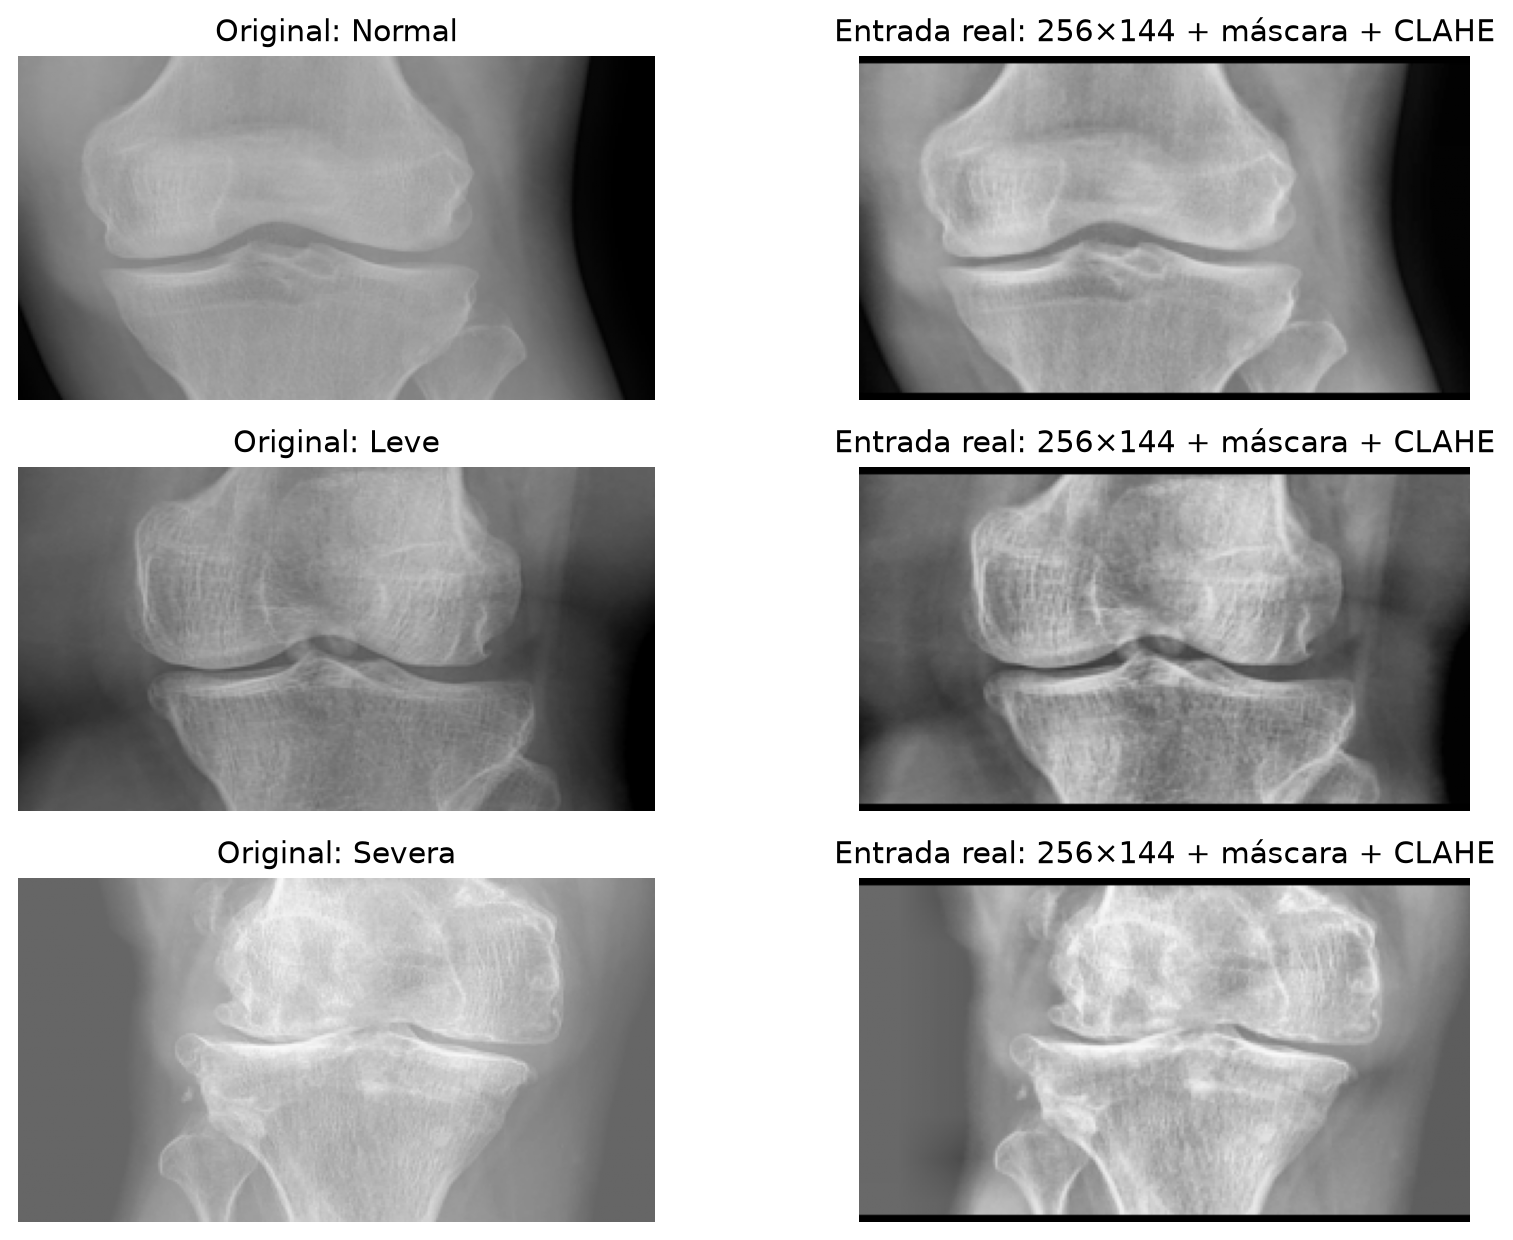

Matrices: {'X_train_tabular': [1103, 288], 'X_train_flat': [1103, 2304], 'X_val_tabular': [236, 288], 'X_val_flat': [236, 2304], 'X_test_tabular': [237, 288], 'X_test_flat': [237, 2304]}


In [15]:
fig, axes = plt.subplots(3, 2, figsize=(10, 7))

for i, row in enumerate(
    manifest.groupby("target").first().reset_index().iloc[[0, 2, 4]].itertuples()
):
    image = cv2.imread(str(ROOT / row.path), 0)
    _, preview, _ = extract_image_features(image)
    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].imshow(preview, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"Original: {LABELS[row.target]}")
    axes[i, 1].set_title("Entrada real: 256×144 + máscara + CLAHE")
    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()

figure("acondicionamiento_radiografias.png")

print("Matrices:", {k: list(v.shape) for k, v in payload.items() if k.startswith("X_")})


## 16. Experimento previo de relleno

La tabla histórica compara cuatro representaciones con SVM C=10 y ANOVA160 sobre train/validación. El 4,83 % es relleno añadido medio, no todo el fondo original. Ese experimento no es el modelo final ni prueba que mejoren todas las métricas.

In [16]:
display(pd.read_csv(ROOT / "reports/padding_experiment/validation_comparison.csv"))


,method,target_height,target_width,masked_statistics,raw_features,selected_features,artificial_padding_pct,validation_f1_macro,validation_accuracy,validation_balanced_accuracy
0,Cuadrado actual,256,256,False,320,160,46.466580,0.588111,0.597458,0.583888
1,Cuadrado con máscara,256,256,True,320,160,46.466580,0.585334,0.593220,0.580720
2,Rectangular,144,256,False,288,160,4.829475,0.589458,0.601695,0.590069
3,Rectangular con máscara,144,256,True,288,160,4.829475,0.603059,0.618644,0.605052
